<a href="https://colab.research.google.com/github/eduardozurek/ia/blob/main/_009_SVM_maquinas_de_soporte_vectorial/01_SVM_Kernel_Lineal_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## MÁQUINAS DE SOPORTE VECTORIAL - SVM - SUPPORT-VECTOR MACHINES
### Las SVM son separadores no lineales que se construyen a partir de separadores lineales y se generalizan con la aplicación de kernels. Las SVM permiten encontrar límites entre conjuntos que se sobrelapan.

### Las implementaciones presentadas aquí se basan en el capítulo 12 de:

[1]	H. Trevor, T. Robert, y F. JH, The elements of statistical learning: data mining, inference, and prediction. New York, NY: Springer, 2009.

### También es muy buena la descripción presentada en:
https://towardsdatascience.com/understanding-support-vector-machine-part-1-lagrange-multipliers-5c24a52ffc5e
### Y
https://towardsdatascience.com/understanding-support-vector-machine-part-2-kernel-trick-mercers-theorem-e1e6848c6c4d

### Y la clase de MIT-OCW del Dr. Patrick Winston:
https://www.youtube.com/watch?v=_PwhiWxHK8o


     pcost       dcost       gap    pres   dres
 0: -6.5477e-01 -1.5036e+00  7e+00  2e+00  2e+00
 1: -4.4907e-01 -1.2185e+00  8e-01  4e-16  8e-16
 2: -6.0670e-01 -6.6082e-01  5e-02  1e-16  2e-15
 3: -6.1893e-01 -6.2281e-01  4e-03  1e-16  1e-15
 4: -6.1943e-01 -6.1962e-01  2e-04  2e-16  1e-15
 5: -6.1943e-01 -6.1943e-01  2e-06  1e-16  8e-16
 6: -6.1943e-01 -6.1943e-01  2e-08  2e-16  8e-16
Optimal solution found.


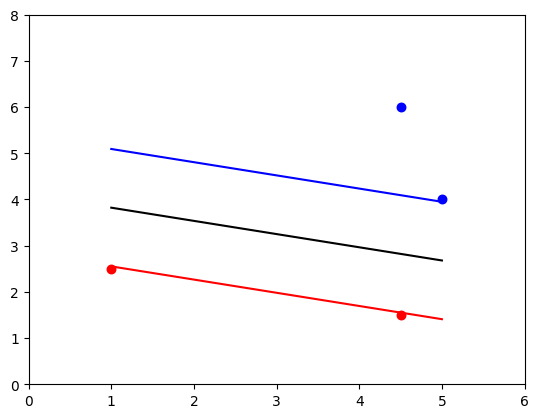

In [ ]:
import numpy as np
from cvxopt import matrix, solvers
import matplotlib.pyplot as plt

# Datos de entrada
x = np.array([[1, 2.5], [4.5, 1.5], [5, 4], [4.5, 6]])
y = np.array([-1, -1, 1, 1])
n = x.shape[0]

# Construcción de las matrices para programación cuadrática
H = np.zeros((n, n))
for k in range(n):
    for l in range(n):
        # Kernel Lineal
        H[k, l] = y[k] * y[l] * np.dot(x[k], x[l])
H = 0.5 * H
q = -np.ones(n)
A = y.reshape(1, -1).astype(float)
b = np.zeros(1)
G = -np.eye(n)
h = np.zeros(n)

# Convertir a matrices cvxopt
H = matrix(H)
q = matrix(q)
A = matrix(A)
b = matrix(b)
G = matrix(G)
h = matrix(h)

# Resolver el problema de programación cuadrática
sol = solvers.qp(H, q, G, h, A, b)
alphas = np.array(sol['x'])

umbral = 1e-5
indice=alphas>umbral
indice=indice.T
indice=indice[0]
indice
# Vectores de soporte
xt = x[indice]
yt = y[indice]

# Calcular w
w = np.sum(alphas * y.reshape(-1, 1) * x, axis=0) / 2
# Calcular el ancho
ancho = 2 / np.linalg.norm(w)
# Calcular b
t = np.dot(xt, w) - yt
b = np.mean(t)

# Crear líneas para graficar
x1 = np.linspace(1, 5, num=50)
y1 = -x1 * w[0] / w[1] + b + 1
y2 = y1 - ancho / 2
y3 = y1 + ancho / 2

# Graficar
plt.scatter(x[y < 0, 0], x[y < 0, 1], color='r', marker='.', s=150)
plt.scatter(x[y >= 0, 0], x[y >= 0, 1], color='b', marker='.', s=150)
plt.plot(x1, y1, 'k')
plt.plot(x1, y2, 'r')
plt.plot(x1, y3, 'b')
plt.xlim([0, 6])
plt.ylim([0, 8])
plt.show()